# C0 · ISBI 2015 · Extra-low · arm R: arm-level analysis only (§10, corrected)

Re-runs the arm-level analysis of `C0_ISBI2015_Extra-low_R.ipynb` from the finished runs in `RUN_ROOT`, **without training**.
It uses the corrected §10 (cells A and B: usable-cell rule, tier status, failures by width, σ₀ check by definition,
robust baseline axes, lock released on error). Runs on a laptop CPU in a few minutes; a GPU is used if one is visible.

What it needs in `RUN_ROOT/<run_id>/`: `DONE`, `config.json`, `summary_final.csv`, `predictions_test.csv.gz` and the
hashed checkpoints (`final_<sha8>.pt`, `snap_e50pct_<sha8>.pt`, `snap_e75pct_<sha8>.pt`). The analysis itself reads the saved
test predictions; the models are loaded only to verify them:

1. **Setup** cells are copied verbatim from the training notebook, so the protocol hash must come out as `23ad729f023ffcdb`.
2. **Checkpoint check:** every checkpoint is re-hashed and must match its file-name suffix, `config.json` and `DONE`.
3. **Re-inference check:** one run's final model predicts `REINFER_N_IMAGES` test images again; the predictions must agree
   with the saved ones (small differences come from CPU fp32 vs GPU bf16).
4. **§10** with the corrected cells. The earlier analysis outputs are moved to `arm_R_summary/_old_<timestamp>/`; the frozen
   baseline-axes file stays in place and the new code asserts that it reproduces it.

Outputs (in `RUN_ROOT/arm_R_summary/`): `tier_status.json`, `fail_by_width.csv`, `sigma0_decision.json`, `q2_size_response.csv`,
`accuracy_by_width.csv`, `baseline_axes_ISBI2015_Extra-low.csv`, `arm_R_overview.png` and the tables of the original §10.

In [1]:
from pathlib import Path
import os

DATASET = "ISBI 2015"
TIER = "Extra-low"
ARM = "R"

RUN_IDS = "all"         # "all" or a list of run_id strings from the run table (§1)
SMOKE_TEST = False      # True: synthetic data, tiny UNet, 4 epochs; checks the pipeline only, results meaningless

def _repo_root():
    """Walk up from the notebook folder to the repo root (the folder holding weights/ and data/)."""
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "weights").is_dir() and (q / "data").is_dir():
            return q
    return None

_REPO = _repo_root()
# Inside the project's Docker image the repo is mounted at /tf; outside it, paths are found relative to the repo root.
DATA_ROOT = os.environ.get("ISBI_ROOT", "/tf/data/ISBI2015" if os.path.isdir("/tf/data/ISBI2015")
                           else str(_REPO / "data" / "ISBI2015") if _REPO else "data/ISBI2015")
RUN_ROOT = os.environ.get("C0_RUN_ROOT", "/tf/weights/C0/ISBI2015_Extra-low" if os.path.isdir("/tf/weights/C0/ISBI2015_Extra-low")
                          else str(_REPO / "weights" / "C0" / "ISBI2015_Extra-low") if _REPO else "weights/C0/ISBI2015_Extra-low")

SIGMA0_PX = 5.0         # PROVISIONAL σ₀ in canvas pixels (canvas 0.3125 mm/px -> 1.56 mm). Register before run 1.
EPOCHS = 800
BATCH_SIZE = 4
NUM_WORKERS = 0         # no training in this notebook
GPU = None              # physical GPU index for this notebook (e.g. 0); None = all visible GPUs, training uses the first
FORCE_REWRITE_AXES = False   # baseline_axes csv is frozen once written; True overwrites it (only before any A arm has started)
# --- analysis-only settings (not part of PROTOCOL, so the hash is unaffected) ---
VERIFY_CHECKPOINTS = True    # re-hash every saved checkpoint and match it to its file name, config.json and DONE
REINFER_RUN = "C0_ISBI2015_Extra-low_R_w1.00_s1"   # reload this run's final model and re-predict a few test images
REINFER_N_IMAGES = 8         # 0 skips the re-inference check; UNet-64 on CPU takes a few seconds per image
ARCHIVE_OLD_SUMMARY = True   # first run only: move the earlier analysis outputs to arm_R_summary/_old_<timestamp>/
CLEAR_LOCK = True            # no training notebooks share RUN_ROOT now, so a leftover .analysis.lock is stale

## 1. Setup (verbatim from the training notebook)

In [2]:
import sys
if GPU is not None:
    # must happen before PyTorch initialises CUDA in this kernel
    if "torch" in sys.modules and sys.modules["torch"].cuda.is_initialized():
        raise RuntimeError("GPU can only be chosen before PyTorch starts: restart the kernel and run from the top.")
    os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU)
import json, math, re, time, hashlib, platform, subprocess, warnings, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

cv2.setNumThreads(0)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    # Fail fast if this PyTorch build has no kernels for the GPU (e.g. Blackwell sm_120 with a cu121/cu124 wheel)
    _maj, _min = torch.cuda.get_device_capability(0)
    _arch, _built = f"sm_{_maj}{_min}", torch.cuda.get_arch_list()
    if _arch not in _built:
        raise RuntimeError(f"{torch.cuda.get_device_name(0)} is {_arch}, but this PyTorch {torch.__version__} "
                           f"(CUDA {torch.version.cuda}) only has kernels for {_built}. For Blackwell (sm_120) install "
                           "PyTorch >= 2.7 built for CUDA >= 12.8, e.g. pip install --upgrade torch torchvision "
                           "--index-url https://download.pytorch.org/whl/cu128, then restart the kernel.")
    _ = (torch.ones(256, 256, device=DEVICE) @ torch.ones(256, 256, device=DEVICE)).sum().item()
if GPU is not None and DEVICE.type == "cuda":
    assert torch.cuda.device_count() == 1, f"expected only GPU {GPU} to be visible, got {torch.cuda.device_count()}"
if os.name == "nt" or SMOKE_TEST:
    NUM_WORKERS = 0          # notebook-defined Dataset classes cannot be pickled to spawned workers

LANDMARKS = ["sella", "nasion", "orbitale", "porion", "subspinale (A)", "supramentale (B)", "pogonion",
             "menton", "gnathion", "gonion", "lower incisal incision", "upper incisal incision", "upper lip",
             "lower lip", "subnasale", "soft-tissue pogonion", "posterior nasal spine", "anterior nasal spine",
             "articulare"]
K = len(LANDMARKS)

PROTOCOL = {
    # data
    "dataset": "ISBI 2015 cephalometric challenge (Wang et al., MedIA 2016)",
    "n_landmarks": K, "pixel_mm": 0.1,
    "split": {"train": [1, 150], "test1": [151, 300], "test2": [301, 400]},
    "ground_truth": "mean of senior and junior annotations",                         # PROVISIONAL
    "canvas_hw": [768, 640],
    "resize": "uniform scale s = min(768/H, 640/W); Gaussian pre-blur sigma 0.4/s; warpAffine bilinear, "
              "pixel-centre map x_c = s*(u+0.5)-0.5; zero pad right/bottom",
    "intensity": "[0,1] then per-sample z-score over the canvas",
    # network
    "tier": "Extra-low", "backbone": "UNet, base width 8, 4 levels, 3x3 conv + BN + ReLU, 2x2 transposed conv, "
                                "1x1 head, heatmaps at input resolution, no output activation",
    # target and loss
    "target": "unnormalised Gaussian exp(-0.5 d^T S^-1 d), peak 1, S in canvas px^2; the rotation part of the "
              "augmentation is applied to S (R S R^T), the scale part is not",
    "loss": "per-channel sum of squared error divided by that channel's analytic target mass 2*pi*sqrt(det S); "
            "landmarks outside the canvas after augmentation are excluded; mean over the remaining channels and batch",
    # optimisation
    "optimiser": {"name": "AdamW", "lr": 1e-3, "weight_decay": 1e-4, "warmup_epochs": 5,
                  "schedule": "cosine to 1e-6 per iteration"},                       # PROVISIONAL
    "epochs": EPOCHS, "batch_size": BATCH_SIZE, "drop_last": True,
    "amp": "bf16 autocast if supported, else fp16 with GradScaler",
    "augmentation": {"rot_deg": 10.0, "scale": [0.9, 1.1], "shift_frac": 0.05, "contrast": 0.2,
                     "brightness": 0.2, "gamma": [0.8, 1.25], "hflip": False},       # PROVISIONAL
    "seed_streams": "seed -> model init (torch); per-epoch order and per-sample augmentation from "
                    "numpy default_rng([seed, epoch, index]) so arms with equal seed see identical data",
    "checkpoint_used": "final epoch, no selection; fp16 snapshots at 50% and 75% for a post-hoc convergence report",
    "checkpoint_naming": "<stem>_<last 8 hex of the file's SHA-256>.pt (stem = final, snap_e50pct, snap_e75pct); "
                         "full SHA-256 in config.json; suffix re-verified on every load",
    "convergence_check": "MRE on 20 fixed training images (no augmentation) every 25 epochs; converged if the "
                         "mean of the last 4 checks is within 2% of the mean of the 4 before",
    # decoding and evaluation
    "decoders": ["argmax", "quadratic", "softargmax_local", "gaussfit"],
    "primary_decoder": "quadratic",                                                  # PROVISIONAL (fixed in WP0)
    "decoder_window_radius_px": 15,                                                  # PROVISIONAL, same in every arm
    "gross_failure_mm": 4.0, "sdr_mm": [2.0, 2.5, 3.0, 4.0],
    "error_frame": "original image, x right, y down, mm; angles from +x towards +y",
}

if SMOKE_TEST:
    RUN_ROOT = str(Path("c0_smoke_runs").resolve())
    DATA_ROOT = str(Path(RUN_ROOT) / "_synthetic_isbi")
    EPOCHS, SIGMA0_PX = 4, 1.5   # 4 so the 50% and 75% snapshots are distinct epochs
    PROTOCOL.update({"canvas_hw": [96, 80], "epochs": EPOCHS, "gross_failure_mm": 1e9,
                     "decoder_window_radius_px": 4, "smoke_test": True})
UNET_BASE = 8              # Extra-low tier: UNet-8 (also used by the smoke test)

PROTOCOL_HASH = hashlib.sha256(json.dumps(PROTOCOL, sort_keys=True).encode()).hexdigest()[:16]
H_C, W_C = PROTOCOL["canvas_hw"]
MM = PROTOCOL["pixel_mm"]
R_WIN = PROTOCOL["decoder_window_radius_px"]
Path(RUN_ROOT).mkdir(parents=True, exist_ok=True)

def _git_commit():
    for d in ("/tf", "."):
        try:
            return subprocess.check_output(["git", "-C", d, "rev-parse", "HEAD"], stderr=subprocess.DEVNULL,
                                           text=True).strip()
        except Exception:
            pass
    return None

ENV_INFO = {
    "python": platform.python_version(), "torch": torch.__version__, "cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "gpu_arch": _arch if DEVICE.type == "cuda" else None,
    "torch_arch_list": torch.cuda.get_arch_list() if DEVICE.type == "cuda" else None,
    "opencv": cv2.__version__, "numpy": np.__version__, "git_commit": _git_commit(),
    "host": platform.node(), "cuda_visible_devices": os.environ.get("CUDA_VISIBLE_DEVICES"),
}
AMP_DTYPE = (torch.bfloat16 if (DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()) else
             torch.float16 if DEVICE.type == "cuda" else None)
torch.backends.cudnn.benchmark = DEVICE.type == "cuda"
print("protocol", PROTOCOL_HASH, "| device", ENV_INFO["gpu"], "| amp", AMP_DTYPE, "| smoke", SMOKE_TEST)

protocol 23ad729f023ffcdb | device cpu | amp None | smoke False


In [3]:
assert PROTOCOL_HASH == "23ad729f023ffcdb", f"protocol hash {PROTOCOL_HASH} is not the one the runs used"
print("RUN_ROOT", RUN_ROOT, "| DATA_ROOT", DATA_ROOT)

RUN_ROOT C:\Users\nearl\Desktop\probable-umbrella\weights\C0\ISBI2015_Extra-low | DATA_ROOT C:\Users\nearl\Desktop\probable-umbrella\data\ISBI2015


In [4]:
WIDTHS = {"0.50": 0.5, "0.71": 2 ** -0.5, "1.00": 1.0, "1.41": 2 ** 0.5, "2.00": 2.0}
PAIRED_SEEDS = [1, 2, 3]
AXIS_SEEDS = [101, 102]

def _run_row(wlabel, seed, role):
    w = WIDTHS[wlabel]
    return {"run_id": f"C0_ISBI2015_{TIER}_{ARM}_w{wlabel}_s{seed}", "dataset": DATASET, "tier": TIER,
            "arm": ARM, "width_label": wlabel, "width_mult": w, "sigma_px": w * SIGMA0_PX,
            "sigma_mm_original": None if SMOKE_TEST else w * SIGMA0_PX * MM / (H_C / 2400.0),
            "seed": seed, "role": role}

rows = [_run_row("1.00", s, "B0 axis-definition (never a paired baseline)") for s in AXIS_SEEDS]
rows += [_run_row("1.00", s, "B0 paired baseline") for s in PAIRED_SEEDS]
rows += [_run_row(wl, s, "size sweep") for wl in ["0.50", "0.71", "1.41", "2.00"] for s in PAIRED_SEEDS]
RUN_TABLE = pd.DataFrame(rows)
assert len(RUN_TABLE) == 17 and RUN_TABLE.run_id.is_unique
RUN_TABLE.to_csv(Path(RUN_ROOT) / "run_table_arm_R.csv", index=False)
RUN_TABLE[["run_id", "width_mult", "sigma_px", "sigma_mm_original", "seed", "role"]]

,run_id,width_mult,sigma_px,sigma_mm_original,seed,role
0,C0_ISBI2015_Extra-low_R_w1.00_s101,1.000000,5.000000,1.562500,101,B0 axis-definition (never a paired baseline)
1,C0_ISBI2015_Extra-low_R_w1.00_s102,1.000000,5.000000,1.562500,102,B0 axis-definition (never a paired baseline)
2,C0_ISBI2015_Extra-low_R_w1.00_s1,1.000000,5.000000,1.562500,1,B0 paired baseline
3,C0_ISBI2015_Extra-low_R_w1.00_s2,1.000000,5.000000,1.562500,2,B0 paired baseline
4,C0_ISBI2015_Extra-low_R_w1.00_s3,1.000000,5.000000,1.562500,3,B0 paired baseline
5,C0_ISBI2015_Extra-low_R_w0.50_s1,0.500000,2.500000,0.781250,1,size sweep
6,C0_ISBI2015_Extra-low_R_w0.50_s2,0.500000,2.500000,0.781250,2,size sweep
7,C0_ISBI2015_Extra-low_R_w0.50_s3,0.500000,2.500000,0.781250,3,size sweep
8,C0_ISBI2015_Extra-low_R_w0.71_s1,0.707107,3.535534,1.104854,1,size sweep
9,C0_ISBI2015_Extra-low_R_w0.71_s2,0.707107,3.535534,1.104854,2,size sweep


In [5]:
def make_synthetic_isbi(root, n=400, H=480, W=387, seed=0):
    """Smoke-test data in the challenge layout: blurred blobs at jittered template positions."""
    rng = np.random.default_rng(seed)
    root = Path(root)
    template = np.stack([rng.uniform(0.15 * W, 0.85 * W, K), rng.uniform(0.15 * H, 0.85 * H, K)], 1)
    for i in range(1, n + 1):
        sub = "TrainingData" if i <= 150 else "Test1Data" if i <= 300 else "Test2Data"
        (root / "RawImage" / sub).mkdir(parents=True, exist_ok=True)
        pts = template + rng.normal(0, 6, template.shape)
        img = rng.normal(40, 8, (H, W)).astype(np.float32)
        for k, (x, y) in enumerate(pts):
            cv2.circle(img, (int(round(x)), int(round(y))), 3 + k % 4, 220.0, -1)
        img = cv2.GaussianBlur(img, (0, 0), 1.5)
        cv2.imwrite(str(root / "RawImage" / sub / f"{i:03d}.bmp"), np.clip(img, 0, 255).astype(np.uint8))
        for who, jit in (("400_senior", 0.0), ("400_junior", 1.0)):
            (root / "AnnotationsByMD" / who).mkdir(parents=True, exist_ok=True)
            p = pts + rng.normal(0, jit, pts.shape)
            lines = [f"{int(round(x))},{int(round(y))}" for x, y in p] + ["1"] * 8
            (root / "AnnotationsByMD" / who / f"{i:03d}.txt").write_text("\n".join(lines))

if SMOKE_TEST and not (Path(DATA_ROOT) / "RawImage").exists():
    make_synthetic_isbi(DATA_ROOT)

def find_isbi_files(root):
    root = Path(root)
    assert root.exists(), f"DATA_ROOT not found: {root}"
    imgs, ann = {}, {"senior": {}, "junior": {}}
    for p in root.rglob("*"):
        if not p.is_file() or not p.stem.isdigit():
            continue
        i = int(p.stem)
        if p.suffix.lower() in (".bmp", ".png", ".jpg", ".jpeg", ".tif", ".tiff"):
            assert i not in imgs, f"duplicate image id {i}: {imgs.get(i)} and {p}"
            imgs[i] = p
        elif p.suffix.lower() == ".txt":
            path_l = str(p.parent).lower()
            who = "senior" if "senior" in path_l else "junior" if "junior" in path_l else None
            if who:
                ann[who][i] = p
    need = set(range(1, 401))
    for name, d in (("images", imgs), ("senior", ann["senior"]), ("junior", ann["junior"])):
        missing = need - set(d)
        assert not missing, f"{name}: {len(missing)} ids missing, e.g. {sorted(missing)[:5]}"
    return imgs, ann

def read_annotation(p):
    pts = []
    for line in Path(p).read_text(errors="ignore").splitlines():
        nums = re.findall(r"-?\d+(?:\.\d+)?", line)
        if len(nums) >= 2:
            pts.append((float(nums[0]), float(nums[1])))
        if len(pts) == K:
            break
    assert len(pts) == K, f"{p}: found {len(pts)} coordinate lines, expected {K}"
    return np.array(pts, dtype=np.float64)

def to_canvas(img):
    """Uniform scale into the H_C x W_C canvas (pad right/bottom). Returns canvas uint8 and scale s."""
    H, W = img.shape
    s = min(H_C / H, W_C / W)
    blurred = cv2.GaussianBlur(img, (0, 0), 0.4 / s) if s < 1 else img
    M = np.array([[s, 0, 0.5 * s - 0.5], [0, s, 0.5 * s - 0.5]], dtype=np.float64)
    can = cv2.warpAffine(blurred, M, (W_C, H_C), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    return can, s

def orig_to_canvas(u, s):
    return s * (u + 0.5) - 0.5

def canvas_to_orig(x, s):
    return (x + 0.5) / s - 0.5

IMG_FILES, ANN_FILES = find_isbi_files(DATA_ROOT)
DATA = {}
sizes = set()
for i in range(1, 401):
    raw = cv2.imread(str(IMG_FILES[i]), cv2.IMREAD_GRAYSCALE)
    assert raw is not None, IMG_FILES[i]
    sizes.add(raw.shape)
    can, s = to_canvas(raw)
    sen, jun = read_annotation(ANN_FILES["senior"][i]), read_annotation(ANN_FILES["junior"][i])
    gt = 0.5 * (sen + jun)
    DATA[i] = {"img": can, "s": s, "gt_orig": gt, "senior": sen, "junior": jun, "gt_canvas": orig_to_canvas(gt, s),
               "subset": "train" if i <= 150 else "test1" if i <= 300 else "test2"}
TRAIN_IDS = list(range(1, 151))
TEST_IDS = list(range(151, 401))
if not SMOKE_TEST and sizes != {(2400, 1935)}:
    warnings.warn(f"image sizes {sizes} differ from the expected 2400 x 1935; the per-image scale handles this, "
                  "but sigma_mm_original in the run table assumes 2400 px height")

inter_obs_mm = np.array([np.linalg.norm(DATA[i]["senior"] - DATA[i]["junior"], axis=1) for i in TEST_IDS]) * MM
print("images", len(DATA), "| sizes", sizes, "| scale s", round(DATA[1]["s"], 5),
      "| canvas mm/px", round(MM / DATA[1]["s"], 4),
      "| test inter-observer median mm", round(float(np.median(inter_obs_mm)), 3))

images 400 | sizes {(2400, 1935)} | scale s 0.32 | canvas mm/px 0.3125 | test inter-observer median mm 1.414


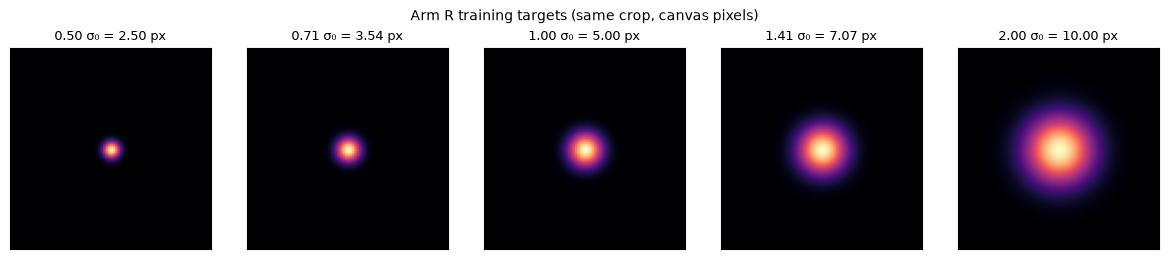

In [6]:
def arm_covariances(arm, width_mult, sigma0_px, k=K):
    """Per-landmark target covariance in the un-augmented canvas frame, px^2, shape (k, 2, 2)."""
    if arm == "R":
        s = width_mult * sigma0_px
        return np.tile(np.eye(2) * s * s, (k, 1, 1))
    raise NotImplementedError("This notebook defines arm R only; the other arms add their own branch here.")

_YY = {}
def make_targets(pts, cov, H=None, W=None):
    """pts (B,K,2) canvas px [x,y]; cov (B,K,2,2). Returns (B,K,H,W) float32 Gaussians with peak 1."""
    H, W = H or H_C, W or W_C
    key = (H, W, str(pts.device))
    if key not in _YY:
        _YY[key] = (torch.arange(W, device=pts.device, dtype=torch.float32).view(1, 1, 1, W),
                    torch.arange(H, device=pts.device, dtype=torch.float32).view(1, 1, H, 1))
    xs, ys = _YY[key]
    inv = torch.linalg.inv(cov.float())
    dx = xs - pts[..., 0, None, None]
    dy = ys - pts[..., 1, None, None]
    q = inv[..., 0, 0, None, None] * dx * dx + 2 * inv[..., 0, 1, None, None] * dx * dy + inv[..., 1, 1, None, None] * dy * dy
    return torch.exp(-0.5 * q)

def in_canvas(pts, H=None, W=None):
    """(B,K) bool: landmark lies inside the canvas (after augmentation)."""
    H, W = H or H_C, W or W_C
    return (pts[..., 0] >= 0) & (pts[..., 0] <= W - 1) & (pts[..., 1] >= 0) & (pts[..., 1] <= H - 1)

def mass_normalised_mse(pred, target, cov, valid=None):
    """Per-channel SSE divided by the analytic target mass 2*pi*sqrt(det S), averaged over valid channels.
    The analytic mass does not shrink when a target is cut by the canvas border, and landmarks pushed off the
    canvas by augmentation (valid=False) are left out of that step's loss instead of dividing by a near-zero mass."""
    mass = 2 * math.pi * torch.sqrt(torch.linalg.det(cov.float()))
    se = ((pred.float() - target) ** 2).sum(dim=(2, 3))
    per = se / mass
    if valid is None:
        return per.mean()
    valid = valid.to(per.dtype)
    return (per * valid).sum() / valid.sum().clamp_min(1)

# check: target mass equals 2*pi*sigma^2 for an interior landmark at every width
_chk = []
for wl, w in WIDTHS.items():
    c = torch.tensor(arm_covariances("R", w, SIGMA0_PX)[None])
    p = torch.tensor([[[W_C / 2 + 0.3, H_C / 2 - 0.2]] * K], dtype=torch.float32)
    t = make_targets(p, c)
    _chk.append(float(t[0, 0].sum()) / (2 * math.pi * (w * SIGMA0_PX) ** 2))
assert all(abs(r - 1) < 0.02 for r in _chk), _chk

fig_t, axs = plt.subplots(1, 5, figsize=(12, 2.6))
p = torch.tensor([[[W_C / 2, H_C / 2]] * K], dtype=torch.float32)
half = min(int(4 * 2.0 * SIGMA0_PX) + 2, H_C // 2, W_C // 2)
for ax, (wl, w) in zip(axs, WIDTHS.items()):
    t = make_targets(p, torch.tensor(arm_covariances("R", w, SIGMA0_PX)[None]))[0, 0].numpy()
    ax.imshow(t[H_C // 2 - half:H_C // 2 + half, W_C // 2 - half:W_C // 2 + half], cmap="magma", vmin=0, vmax=1)
    ax.set_title(f"{wl} σ₀ = {w * SIGMA0_PX:.2f} px", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig_t.suptitle("Arm R training targets (same crop, canvas pixels)", fontsize=10)
fig_t.tight_layout()
fig_t.savefig(Path(RUN_ROOT) / "arm_R_targets.png", dpi=150)

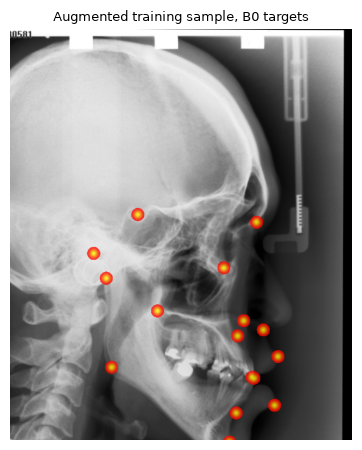

In [7]:
AUG = PROTOCOL["augmentation"]

class TrainSet(torch.utils.data.Dataset):
    def __init__(self, ids, seed, augment=True):
        self.ids, self.seed, self.augment, self.epoch = list(ids), int(seed), augment, 0

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, j):
        d = DATA[self.ids[j]]
        img, pts = d["img"], d["gt_canvas"]
        rot = np.eye(2)
        x = img.astype(np.float32) / 255.0
        if self.augment:
            rng = np.random.default_rng([self.seed, self.epoch, j])
            th = math.radians(rng.uniform(-AUG["rot_deg"], AUG["rot_deg"]))
            sc = math.exp(rng.uniform(math.log(AUG["scale"][0]), math.log(AUG["scale"][1])))
            sh = rng.uniform(-AUG["shift_frac"], AUG["shift_frac"], 2) * np.array([W_C, H_C])
            rot = np.array([[math.cos(th), -math.sin(th)], [math.sin(th), math.cos(th)]])
            A = sc * rot
            c = np.array([(W_C - 1) / 2, (H_C - 1) / 2])
            b = c + sh - A @ c
            M = np.hstack([A, b[:, None]])
            x = cv2.warpAffine(x, M, (W_C, H_C), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
            pts = pts @ A.T + b
            g = math.exp(rng.uniform(math.log(AUG["gamma"][0]), math.log(AUG["gamma"][1])))
            x = np.clip(x, 0, 1) ** g
            x = x * (1 + rng.uniform(-AUG["contrast"], AUG["contrast"])) + rng.uniform(-AUG["brightness"], AUG["brightness"])
        x = (x - x.mean()) / (x.std() + 1e-6)
        return (torch.from_numpy(x[None].astype(np.float32)), torch.from_numpy(pts.astype(np.float32)),
                torch.from_numpy(rot.astype(np.float32)))

def epoch_order(seed, epoch, n):
    return np.random.default_rng([seed, epoch, 10 ** 6]).permutation(n).tolist()

def plain_batch(ids):
    xs = []
    for i in ids:
        x = DATA[i]["img"].astype(np.float32) / 255.0
        xs.append((x - x.mean()) / (x.std() + 1e-6))
    return torch.from_numpy(np.stack(xs)[:, None])

# visual check: one augmented sample with its B0 targets
_ds = TrainSet(TRAIN_IDS, seed=1)
_x, _p, _r = _ds[0]
_cov = torch.tensor(arm_covariances("R", 1.0, SIGMA0_PX)[None]).float()
_t = make_targets(_p[None], _r[None, None] @ _cov @ _r[None, None].transpose(-1, -2))[0].amax(0)
fig_a, ax = plt.subplots(figsize=(4, 4.6))
ax.imshow(_x[0], cmap="gray")
ax.imshow(np.ma.masked_less(_t.numpy(), 0.05), cmap="autumn", alpha=0.8)
ax.set_title("Augmented training sample, B0 targets", fontsize=9)
ax.axis("off")
fig_a.tight_layout()
fig_a.savefig(Path(RUN_ROOT) / "arm_R_augmented_sample.png", dpi=150)

In [8]:
class DoubleConv(nn.Sequential):
    def __init__(self, ci, co):
        super().__init__(nn.Conv2d(ci, co, 3, padding=1, bias=True), nn.BatchNorm2d(co), nn.ReLU(inplace=True),
                         nn.Conv2d(co, co, 3, padding=1, bias=True), nn.BatchNorm2d(co), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=K, base=64, levels=4):
        super().__init__()
        ch = [base * 2 ** i for i in range(levels + 1)]
        self.down = nn.ModuleList()
        c = in_ch
        for i in range(levels):
            self.down.append(DoubleConv(c, ch[i])); c = ch[i]
        self.bottom = DoubleConv(ch[levels - 1], ch[levels])
        self.up = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in reversed(range(levels))])
        self.dec = nn.ModuleList([DoubleConv(2 * ch[i], ch[i]) for i in reversed(range(levels))])
        self.head = nn.Conv2d(ch[0], out_ch, 1)

    def forward(self, x):
        skips = []
        for blk in self.down:
            x = blk(x); skips.append(x); x = F.max_pool2d(x, 2)
        x = self.bottom(x)
        for up, dec, s in zip(self.up, self.dec, reversed(skips)):
            x = dec(torch.cat([up(x), s], 1))
        return self.head(x)

N_PARAMS = sum(p.numel() for p in UNet(base=UNET_BASE).parameters())
if not SMOKE_TEST:
    assert N_PARAMS == 487_307, N_PARAMS
assert H_C % 16 == 0 and W_C % 16 == 0
print("UNet base", UNET_BASE, "| parameters", f"{N_PARAMS / 1e6:.3f} M")

UNet base 8 | parameters 0.487 M


In [9]:
def heatmap_windows(hm, r=None):
    """hm (B,K,H,W) float tensor -> integer peaks (B,K,2) [x,y] and windows (B,K,2r+1,2r+1) as numpy (NaN outside image)."""
    r = r or R_WIN
    B, Kk, H, W = hm.shape
    flat = hm.reshape(B, Kk, -1).argmax(-1)
    iy, ix = (flat // W), (flat % W)
    pad = F.pad(hm, (r, r, r, r), value=float("nan"))
    ar = torch.arange(2 * r + 1, device=hm.device)
    idx_y = (iy[..., None] + ar)[..., None].expand(B, Kk, 2 * r + 1, W + 2 * r)
    rows = torch.gather(pad, 2, idx_y)
    idx_x = (ix[..., None] + ar)[:, :, None, :].expand(B, Kk, 2 * r + 1, 2 * r + 1)
    win = torch.gather(rows, 3, idx_x)
    peaks = torch.stack([ix, iy], -1)
    return peaks.cpu().numpy().astype(np.float64), win.float().cpu().numpy().astype(np.float64)

_GRID = {}
def decode_window(w):
    """w: (2r+1,2r+1) window centred on the integer peak. Returns offsets (dx,dy) per decoder and the fitted covariance."""
    r = w.shape[0] // 2
    out = {"argmax": (0.0, 0.0)}
    peak = w[r, r]
    # quadratic (Taylor step on the log heatmap)
    off = (0.0, 0.0)
    nb = w[r - 1:r + 2, r - 1:r + 2]
    if peak > 0 and np.all(np.isfinite(nb)):
        L = np.log(np.clip(nb, 1e-6 * peak, None))
        gx, gy = (L[1, 2] - L[1, 0]) / 2, (L[2, 1] - L[0, 1]) / 2
        hxx, hyy = L[1, 2] - 2 * L[1, 1] + L[1, 0], L[2, 1] - 2 * L[1, 1] + L[0, 1]
        hxy = (L[2, 2] - L[2, 0] - L[0, 2] + L[0, 0]) / 4
        Hm = np.array([[hxx, hxy], [hxy, hyy]])
        if hxx < 0 and np.linalg.det(Hm) > 0:
            o = -np.linalg.solve(Hm, [gx, gy])
            off = tuple(float(v) for v in np.clip(o, -1, 1))
    out["quadratic"] = off
    # local soft-argmax
    if r not in _GRID:
        g = np.arange(-r, r + 1, dtype=np.float64)
        _GRID[r] = np.meshgrid(g, g)
    gx_, gy_ = _GRID[r]
    pw = np.where(np.isfinite(w), np.clip(w, 0, None), 0.0)
    out["softargmax_local"] = ((pw * gx_).sum() / pw.sum(), (pw * gy_).sum() / pw.sum()) if pw.sum() > 0 else (0.0, 0.0)
    # Gaussian fit (falls back to the quadratic step)
    out["gaussfit"], out["gauss_cov"] = off, (np.nan, np.nan, np.nan)
    m = (np.isfinite(w) & (w > 0.1 * peak)) if peak > 0 else np.zeros(w.shape, bool)
    if m.sum() >= 6:
        X, Y, V = gx_[m], gy_[m], w[m]
        Amat = np.stack([np.ones_like(X), X, Y, X * X, X * Y, Y * Y], 1)
        sw = np.sqrt(V)
        coef, *_ = np.linalg.lstsq(Amat * sw[:, None], np.log(V) * sw, rcond=None)
        A2 = np.array([[coef[3], coef[4] / 2], [coef[4] / 2, coef[5]]])
        if np.all(np.linalg.eigvalsh(A2) < 0):
            S = -0.5 * np.linalg.inv(A2)
            mu = S @ coef[1:3]
            if np.all(np.abs(mu) <= r):
                out["gaussfit"], out["gauss_cov"] = (float(mu[0]), float(mu[1])), (S[0, 0], S[0, 1], S[1, 1])
    return out

# unit check on noiseless Gaussians at sub-pixel positions
_errs = {d: [] for d in PROTOCOL["decoders"]}
for (x0, y0) in [(40.3, 31.7), (52.6, 20.2), (33.5, 44.5)]:
    for sg in (SIGMA0_PX * 2 ** -0.5, SIGMA0_PX):
        cov = torch.tensor(np.eye(2)[None, None] * sg ** 2)
        hm = make_targets(torch.tensor([[[x0, y0]]], dtype=torch.float32), cov, 80, 96)
        pk, win = heatmap_windows(hm)
        dec = decode_window(win[0, 0])
        for d in PROTOCOL["decoders"]:
            _errs[d].append(math.hypot(pk[0, 0, 0] + dec[d][0] - x0, pk[0, 0, 1] + dec[d][1] - y0))
_maxerr = {d: round(max(v), 4) for d, v in _errs.items()}
assert _maxerr["quadratic"] < 0.02 and _maxerr["gaussfit"] < 0.02 and _maxerr["softargmax_local"] < 0.1, _maxerr
print("decoder max error on noiseless Gaussians (px):", _maxerr)

decoder max error on noiseless Gaussians (px): {'argmax': 0.7071, 'quadratic': 0.0, 'softargmax_local': 0.0144, 'gaussfit': 0.0}


In [10]:
@torch.no_grad()
def predict(model, ids, batch=4):
    model.eval()
    recs = []
    for k0 in range(0, len(ids), batch):
        bid = ids[k0:k0 + batch]
        x = plain_batch(bid).to(DEVICE)
        with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
            hm = model(x)
        peaks, wins = heatmap_windows(hm.float())
        for b, i in enumerate(bid):
            d = DATA[i]
            for k in range(K):
                dec = decode_window(wins[b, k])
                for name in PROTOCOL["decoders"]:
                    xc, yc = peaks[b, k, 0] + dec[name][0], peaks[b, k, 1] + dec[name][1]
                    xo, yo = canvas_to_orig(xc, d["s"]), canvas_to_orig(yc, d["s"])
                    dx, dy = (xo - d["gt_orig"][k, 0]) * MM, (yo - d["gt_orig"][k, 1]) * MM
                    recs.append((i, d["subset"], k + 1, name, xo, yo, dx, dy, math.hypot(dx, dy),
                                 wins[b, k, R_WIN, R_WIN], *dec["gauss_cov"]))
    return pd.DataFrame(recs, columns=["image_id", "subset", "landmark", "decoder", "x_pred", "y_pred",
                                       "dx_mm", "dy_mm", "r_mm", "peak", "fit_sxx", "fit_sxy", "fit_syy"])

def _madsd(v):
    return 1.4826 * float(np.median(np.abs(v - np.median(v))))

def spread_stats(dx, dy, fail_mm=None):
    """Spread after the gross-failure cut. Major-axis angle in degrees from +x towards +y (image frame)."""
    fail_mm = PROTOCOL["gross_failure_mm"] if fail_mm is None else fail_mm
    dx, dy = np.asarray(dx, float), np.asarray(dy, float)
    r = np.hypot(dx, dy)
    keep = r <= fail_mm
    out = {"n": len(r), "n_kept": int(keep.sum()), "fail_rate": float(1 - keep.mean()), "mre_mm": float(r.mean())}
    for t in PROTOCOL["sdr_mm"]:
        out[f"sdr_{t:g}mm"] = float((r <= t).mean())
    if keep.sum() >= 5:
        ex, ey = dx[keep], dy[keep]
        C = np.cov(np.stack([ex, ey]))
        ev, V = np.linalg.eigh(C)
        ang = (math.degrees(math.atan2(V[1, 1], V[0, 1])) + 90) % 180 - 90
        out.update({"bias_x_mm": ex.mean(), "bias_y_mm": ey.mean(), "sd_x": math.sqrt(C[0, 0]), "sd_y": math.sqrt(C[1, 1]),
                    "cov_xy": C[0, 1], "sd_iso": math.sqrt(np.trace(C) / 2), "sd_major": math.sqrt(max(ev[1], 0)),
                    "sd_minor": math.sqrt(max(ev[0], 0)), "angle_major_deg": ang,
                    "sd_ratio": math.sqrt(ev[1] / ev[0]) if ev[0] > 0 else np.nan,
                    "madsd_x": _madsd(ex), "madsd_y": _madsd(ey)})
    return out

def summarise(pred):
    rows = []
    for (dec, lm), g in pred.groupby(["decoder", "landmark"]):
        rows.append({"decoder": dec, "landmark": lm, **spread_stats(g.dx_mm, g.dy_mm)})
    for dec, g in pred.groupby("decoder"):   # landmark 0 = all landmarks pooled (accuracy only)
        st = spread_stats(g.dx_mm, g.dy_mm)
        rows.append({"decoder": dec, "landmark": 0, **{k: v for k, v in st.items()
                                                      if k in ("n", "n_kept", "fail_rate", "mre_mm") or k.startswith("sdr")}})
    return pd.DataFrame(rows)

In [11]:
CONV_IDS = sorted(np.random.default_rng(0).choice(TRAIN_IDS, 20, replace=False).tolist())

def lr_at(it, iters_per_epoch, total_iters):
    o = PROTOCOL["optimiser"]
    warm = o["warmup_epochs"] * iters_per_epoch
    if it < warm:
        return o["lr"] * (it + 1) / warm
    prog = (it - warm) / max(1, total_iters - warm)
    return 1e-6 + 0.5 * (o["lr"] - 1e-6) * (1 + math.cos(math.pi * prog))

def file_sha256(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def save_checkpoint(state, out_dir, stem):
    """Save to <stem>_<sha8>.pt, where sha8 = last 8 hex characters of the file's SHA-256.
    Any older <stem>_<8 hex>.pt in the same run folder (e.g. from an interrupted save) is removed first."""
    out_dir = Path(out_dir)
    for old in out_dir.glob(f"{stem}_*.pt"):
        if re.fullmatch(rf"{re.escape(stem)}_[0-9a-f]{{8}}\.pt", old.name):
            old.unlink()
    tmp = out_dir / f"{stem}.pt.tmp"
    torch.save(state, tmp)
    sha = file_sha256(tmp)
    path = out_dir / f"{stem}_{sha[-8:]}.pt"
    os.replace(tmp, path)
    return path, sha

def find_checkpoint(out_dir, stem, verify=True):
    """Return (path, sha256) of the single <stem>_<sha8>.pt in out_dir, or (None, None). Verifies the suffix."""
    hits = [p for p in Path(out_dir).glob(f"{stem}_*.pt")
            if re.fullmatch(rf"{re.escape(stem)}_[0-9a-f]{{8}}\.pt", p.name)]
    if not hits:
        return None, None
    assert len(hits) == 1, f"more than one {stem} checkpoint in {out_dir}: {[p.name for p in hits]}"
    sha = file_sha256(hits[0]) if verify else None
    if verify:
        assert sha[-8:] == hits[0].stem.rsplit("_", 1)[1], f"{hits[0].name}: content does not match its SHA-256 suffix"
    return hits[0], sha

def _grad_scaler():
    enabled = AMP_DTYPE == torch.float16
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)

def train_run(run):
    out = Path(RUN_ROOT) / run["run_id"]
    if (out / "DONE").exists():
        print("skip (done):", run["run_id"]); return
    out.mkdir(parents=True, exist_ok=True)
    seed = int(run["seed"])
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    model = UNet(base=UNET_BASE).to(DEVICE)
    o = PROTOCOL["optimiser"]
    opt = torch.optim.AdamW(model.parameters(), lr=o["lr"], weight_decay=o["weight_decay"])
    scaler = _grad_scaler()
    ds = TrainSet(TRAIN_IDS, seed)
    ipe = len(TRAIN_IDS) // BATCH_SIZE
    total = EPOCHS * ipe
    base_cov = torch.tensor(arm_covariances(ARM, run["width_mult"], SIGMA0_PX), dtype=torch.float32, device=DEVICE)
    start_ep, log = 0, []
    if (out / "last.pt").exists():
        ck = torch.load(out / "last.pt", map_location=DEVICE, weights_only=False)
        assert ck["protocol_hash"] == PROTOCOL_HASH, "protocol changed since this run started"
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        start_ep, log = ck["epoch"] + 1, ck["log"]
        print("resume", run["run_id"], "from epoch", start_ep)
    cfg = {"run": run, "protocol": PROTOCOL, "protocol_hash": PROTOCOL_HASH, "env": ENV_INFO, "sigma0_px": SIGMA0_PX,
           "unet_base": UNET_BASE, "n_params": N_PARAMS, "conv_ids": CONV_IDS,
           "started": dt.datetime.now().isoformat(timespec="seconds")}
    (out / "config.json").write_text(json.dumps(cfg, indent=1, default=str))
    snaps = {max(int(EPOCHS * 0.5) - 1, 0): "e50pct", max(int(EPOCHS * 0.75) - 1, 0): "e75pct"}
    t_run = time.time()
    for ep in range(start_ep, EPOCHS):
        model.train(); ds.epoch = ep
        dl = torch.utils.data.DataLoader(ds, batch_size=BATCH_SIZE, sampler=epoch_order(seed, ep, len(ds)),
                                         num_workers=NUM_WORKERS, drop_last=True, pin_memory=DEVICE.type == "cuda")
        t0, losses, n_off = time.time(), [], 0
        for it_in, (x, p, rot) in enumerate(dl):
            it = ep * ipe + it_in
            for gp in opt.param_groups:
                gp["lr"] = lr_at(it, ipe, total)
            x, p, rot = x.to(DEVICE, non_blocking=True), p.to(DEVICE), rot.to(DEVICE)
            cov = rot[:, None] @ base_cov[None] @ rot[:, None].transpose(-1, -2)
            tgt = make_targets(p, cov)
            with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
                pred = model(x)
            valid = in_canvas(p)
            n_off += int((~valid).sum())
            loss = mass_normalised_mse(pred, tgt, cov, valid)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            losses.append(loss.item())
        rec = {"epoch": ep + 1, "loss": float(np.mean(losses)), "lr": float(opt.param_groups[0]["lr"]),
               "sec": time.time() - t0, "n_landmarks_off_canvas": n_off}
        if (ep + 1) % 25 == 0 or ep + 1 == EPOCHS:
            pr = predict(model, CONV_IDS)
            rec["conv_mre_mm"] = float(pr[pr.decoder == PROTOCOL["primary_decoder"]].r_mm.mean())
        log.append(rec)
        if ep in snaps:
            save_checkpoint({k: v.half() if v.is_floating_point() else v for k, v in model.state_dict().items()},
                            out, f"snap_{snaps[ep]}")
        if (ep + 1) % 50 == 0 or ep + 1 == EPOCHS:
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(), "epoch": ep,
                        "log": log, "protocol_hash": PROTOCOL_HASH}, out / "last.pt")
            pd.DataFrame(log).to_csv(out / "train_log.csv", index=False)
        if ep == start_ep:
            print(f"{run['run_id']}: epoch {ep + 1} took {rec['sec']:.1f} s -> projected "
                  f"{rec['sec'] * (EPOCHS - ep) / 3600:.2f} h for the rest of the run")
    final_path, final_sha = save_checkpoint(model.state_dict(), out, "final")
    lg = pd.DataFrame(log); lg.to_csv(out / "train_log.csv", index=False)
    cm = lg.conv_mre_mm.dropna().values
    converged = bool(len(cm) >= 8 and abs(cm[-4:].mean() - cm[-8:-4].mean()) <= 0.02 * cm[-8:-4].mean())
    # evaluation: final checkpoint (the one used) and snapshots (convergence report only, never selected)
    preds, ckpts = [], {}
    stems = {"final": "final", **{t: f"snap_{t}" for t in sorted(set(snaps.values()))}}
    for tag, stem in stems.items():
        path, sha = find_checkpoint(out, stem)
        assert path is not None, f"{run['run_id']}: expected checkpoint {stem}_<sha8>.pt not found"
        ckpts[tag] = {"file": path.name, "sha256": sha}
        model.load_state_dict({k: v.float() if v.is_floating_point() else v
                               for k, v in torch.load(path, map_location=DEVICE).items()})
        pr = predict(model, TEST_IDS)
        pr.insert(0, "checkpoint_sha8", sha[-8:]); pr.insert(0, "checkpoint", tag); preds.append(pr)
    assert ckpts["final"]["sha256"] == final_sha
    pred = pd.concat(preds, ignore_index=True)
    assert set(pred.checkpoint) == set(stems), f"evaluated {set(pred.checkpoint)}, expected {set(stems)}"
    pred.insert(0, "run_id", run["run_id"])
    pred.to_csv(out / "predictions_test.csv.gz", index=False)
    summ = summarise(pred[pred.checkpoint == "final"])
    summ.insert(0, "checkpoint_sha8", final_sha[-8:]); summ.insert(0, "run_id", run["run_id"])
    summ.to_csv(out / "summary_final.csv", index=False)
    cfg.update({"finished": dt.datetime.now().isoformat(timespec="seconds"),
                "train_hours_this_session": (time.time() - t_run) / 3600,
                "sec_per_epoch_median": float(lg.sec.median()), "converged": converged, "checkpoints": ckpts})
    (out / "config.json").write_text(json.dumps(cfg, indent=1, default=str))
    (out / "last.pt").unlink(missing_ok=True)
    (out / "DONE").write_text(f"{PROTOCOL_HASH}\n{final_path.name}\n{final_sha}\n")
    s0 = summ[(summ.decoder == PROTOCOL["primary_decoder"]) & (summ.landmark == 0)].iloc[0]
    print(f"done {run['run_id']} -> {final_path.name}: MRE {s0.mre_mm:.3f} mm, SDR 2 mm {s0.sdr_2mm:.3f}, "
          f"gross failures {s0.fail_rate:.3f}, converged {converged}, {lg.sec.median() * EPOCHS / 3600:.2f} h/run")

## 2. Checkpoint check
Every checkpoint is re-hashed; the SHA-256 must match its file-name suffix, `config.json` and (for the final model) `DONE`.

In [12]:
rows = []
for rid in RUN_TABLE.run_id:
    d = Path(RUN_ROOT) / rid
    assert (d / "DONE").exists(), f"{rid}: not finished (no DONE)"
    done = (d / "DONE").read_text().split()
    cfg = json.loads((d / "config.json").read_text())
    assert done[0] == PROTOCOL_HASH == cfg["protocol_hash"], f"{rid}: protocol hash differs"
    rec = {"run_id": rid, "converged": cfg.get("converged"), "train_h": round(cfg.get("train_hours_this_session", float("nan")), 2)}
    for tag, stem in (("final", "final"), ("e50pct", "snap_e50pct"), ("e75pct", "snap_e75pct")):
        path, sha = find_checkpoint(d, stem, verify=VERIFY_CHECKPOINTS)
        assert path is not None, f"{rid}: {stem}_<sha8>.pt missing"
        if VERIFY_CHECKPOINTS:
            assert sha == cfg["checkpoints"][tag]["sha256"], f"{rid}: {path.name} differs from config.json"
            if tag == "final":
                assert sha == done[2] and path.name == done[1], f"{rid}: final checkpoint differs from DONE"
        rec[tag] = path.name
    rows.append(rec)
CKPT_TABLE = pd.DataFrame(rows)
print(f"{len(CKPT_TABLE)} runs, {3 * len(CKPT_TABLE)} checkpoints",
      "verified (SHA-256 = file-name suffix = config.json = DONE)" if VERIFY_CHECKPOINTS else "found (not re-hashed)")
CKPT_TABLE

17 runs, 51 checkpoints verified (SHA-256 = file-name suffix = config.json = DONE)


,run_id,converged,train_h,final,e50pct,e75pct
0,C0_ISBI2015_Extra-low_R_w1.00_s101,True,0.88,final_4e08d0ac.pt,snap_e50pct_fea83025.pt,snap_e75pct_c7fefe87.pt
1,C0_ISBI2015_Extra-low_R_w1.00_s102,True,0.88,final_341c432b.pt,snap_e50pct_86956d0c.pt,snap_e75pct_572f6153.pt
2,C0_ISBI2015_Extra-low_R_w1.00_s1,False,0.88,final_7bb20c1c.pt,snap_e50pct_0f6df629.pt,snap_e75pct_38024282.pt
3,C0_ISBI2015_Extra-low_R_w1.00_s2,True,0.83,final_bb98a5d7.pt,snap_e50pct_a056e459.pt,snap_e75pct_52da8b77.pt
4,C0_ISBI2015_Extra-low_R_w1.00_s3,True,0.86,final_8184a65b.pt,snap_e50pct_efe49f50.pt,snap_e75pct_77a27167.pt
5,C0_ISBI2015_Extra-low_R_w0.50_s1,False,0.85,final_d0bc8582.pt,snap_e50pct_67e64380.pt,snap_e75pct_78ce3477.pt
6,C0_ISBI2015_Extra-low_R_w0.50_s2,False,0.85,final_28cca6ef.pt,snap_e50pct_4abcb34f.pt,snap_e75pct_df119c31.pt
7,C0_ISBI2015_Extra-low_R_w0.50_s3,True,0.86,final_9edf44a0.pt,snap_e50pct_bb6447db.pt,snap_e75pct_7a103042.pt
8,C0_ISBI2015_Extra-low_R_w0.71_s1,True,0.86,final_1769b1df.pt,snap_e50pct_1a433192.pt,snap_e75pct_de8a2afb.pt
9,C0_ISBI2015_Extra-low_R_w0.71_s2,False,0.81,final_840ffdd1.pt,snap_e50pct_d3c91bc7.pt,snap_e75pct_c17bf2d1.pt


## 3. Re-inference check
The final model of `REINFER_RUN` predicts the first `REINFER_N_IMAGES` test images again. At least 95 % of the primary-decoder points should lie within 0.1 mm of the saved predictions (CPU fp32 vs GPU bf16 can move a few peaks); otherwise a warning is shown.

In [13]:
if REINFER_N_IMAGES > 0:
    d = Path(RUN_ROOT) / REINFER_RUN
    path, _ = find_checkpoint(d, "final", verify=False)
    model = UNet(base=UNET_BASE).to(DEVICE)
    model.load_state_dict({k: v.float() if v.is_floating_point() else v
                           for k, v in torch.load(path, map_location=DEVICE).items()})
    ids = TEST_IDS[:REINFER_N_IMAGES]
    t0 = time.time()
    new = predict(model, ids)
    t_inf = time.time() - t0
    old = pd.read_csv(d / "predictions_test.csv.gz")
    old = old[(old.checkpoint == "final") & old.image_id.isin(ids)]
    m = new.merge(old, on=["image_id", "landmark", "decoder"], suffixes=("_new", "_saved"))
    assert len(m) == len(ids) * K * len(PROTOCOL["decoders"]), len(m)
    m["shift_mm"] = np.hypot(m.x_pred_new - m.x_pred_saved, m.y_pred_new - m.y_pred_saved) * MM
    pd_ = m[m.decoder == PROTOCOL["primary_decoder"]]
    agree = float((pd_.shift_mm <= 0.1).mean())
    print(f"{REINFER_RUN}: {len(ids)} images re-predicted on {ENV_INFO['gpu']} in {t_inf:.0f} s | primary decoder: "
          f"median shift {pd_.shift_mm.median():.4f} mm, max {pd_.shift_mm.max():.3f} mm, {agree:.1%} of points within 0.1 mm "
          f"| MRE new {pd_.r_mm_new.mean():.3f} vs saved {pd_.r_mm_saved.mean():.3f} mm")
    if agree < 0.95:
        # near-flat heatmaps (a run that lost landmarks) can move their argmax between CPU fp32 and GPU bf16
        warnings.warn("re-predictions disagree with the saved ones for more than 5 % of points: check data, preprocessing "
                      "and checkpoint, unless this run has many gross failures")
    del model

C0_ISBI2015_Extra-low_R_w1.00_s1: 8 images re-predicted on cpu in 2 s | primary decoder: median shift 0.0379 mm, max 220.093 mm, 82.2% of points within 0.1 mm | MRE new 38.223 vs saved 39.529 mm


<cell 13>:23: UserWarning: re-predictions disagree with the saved ones for more than 5 % of points: check data, preprocessing and checkpoint, unless this run has many gross failures


## 10. Arm-level analysis (runs once all 17 runs are done)

* **Per run and landmark:** SD after the 4 mm gross-failure cut (primary decoder), failure rate, MRE, SDR.
* **Q2:** per landmark, OLS of log SD_iso on u = log w with a quadratic term, over the 15 paired runs. β_i is the slope at σ₀
  (u = 0). σ_i,best = σ₀ · exp(−b/2c) when the curve is convex (c > 0) and the minimum lies inside the grid; otherwise the best grid
  width is reported and flagged. The same fit is done separately for SD_x and SD_y as the reference for the oval arms' separability check.
* **Usable cells (analysis rule; added after the first 0.5 × σ₀ runs at High showed 30–45 % gross failures, before
  any size-response fit was computed):** a run × landmark cell enters the Q2 fit and the
  pooled curve only if at most 5 % of its 250 test errors exceed 4 mm (`MAX_FAIL_CELL`). Failure rates per width are reported
  alongside (`fail_by_width.csv`), because a narrow target that loses the landmark is a result of its own (the detectability floor).
* **Tier status:** the tier qualifies for the transfer and capacity analyses only if every 1 × σ₀ run has ≤ 5 % gross failures
  (`tier_status.json`). A tier that fails is still analysed, descriptively.
* **σ₀ check (by definition, σ₀ is the round baseline's best width):** reference landmarks are those usable in all three paired
  1 × σ₀ runs; widths where ≥ 90 % of the reference-landmark cells are usable are eligible (amendment of 5 Oct 2026, made after
  the High failure table showed four landmarks failing > 5 % at every width; the rule uses failure rates only); the
  pooled curve (mean log SD over the landmarks usable at every eligible width) picks the best one. If it is not 1 × σ₀,
  `sigma0_decision.json` lists the new σ₀, which existing runs map onto the new grid, and the extra runs needed (missing widths
  × 3 seeds, plus 2 new axis-definition runs). If the best is the widest eligible width, the grid is extended first.
* **Baseline axes:** errors after the cut from the two axis-definition seeds (each centred on its own mean) are pooled per landmark.
  The major eigenvector gives the axis, and the SD ratio decides whether it is defined (≥ 1.15, plan §4.3). The file is frozen once written.
  Landmarks below 1.15 get the image x-axis as a placeholder orientation; the plan's contour-tangent option needs contours, which ISBI does not provide.
* **Baseline anisotropy (descriptive):** SD ratios under B0 across all five B0 runs.

Earlier analysis outputs are moved aside first (the baseline-axes file stays: it is frozen, and cell A checks that it is reproduced).

In [14]:
import shutil
AGG = Path(RUN_ROOT) / "arm_R_summary"
AGG.mkdir(exist_ok=True)
if CLEAR_LOCK and (AGG / ".analysis.lock").exists():
    (AGG / ".analysis.lock").unlink()
    print("removed stale", AGG / ".analysis.lock")
old_files = [p for p in AGG.iterdir() if p.is_file() and not p.name.startswith("baseline_axes_") and p.name != ".analysis.lock"]
done_before = sorted(AGG.glob("_old_*"))
if done_before:
    print("earlier outputs were already archived in", done_before[-1].name, "- this run overwrites the corrected outputs")
elif ARCHIVE_OLD_SUMMARY and old_files:
    arch = AGG / f"_old_{dt.datetime.now():%Y%m%d_%H%M%S}"
    arch.mkdir()
    for p in old_files:
        shutil.move(str(p), arch / p.name)
    print(f"moved {len(old_files)} earlier outputs to {arch}")
print("frozen axes file kept:", [p.name for p in AGG.glob("baseline_axes_*.csv")])

earlier outputs were already archived in _old_20261005_100104 - this run overwrites the corrected outputs
frozen axes file kept: ['baseline_axes_ISBI2015_Extra-low.csv']


In [15]:
def load_done_runs():
    summ, preds = [], []
    for rid in RUN_TABLE.run_id:
        d = Path(RUN_ROOT) / rid
        if (d / "DONE").exists():
            done = (d / "DONE").read_text().split()
            assert done[0] == PROTOCOL_HASH, f"{rid} ran under a different protocol"
            assert len(done) >= 3 and (d / done[1]).exists() and done[2].endswith(done[1][-11:-3]), \
                f"{rid}: DONE marker does not name an existing hashed final checkpoint"
            summ.append(pd.read_csv(d / "summary_final.csv"))
            p = pd.read_csv(d / "predictions_test.csv.gz")
            preds.append(p[p.checkpoint == "final"])
    return (pd.concat(summ, ignore_index=True) if summ else None), (pd.concat(preds, ignore_index=True) if preds else None)

SUMM, PRED = load_done_runs()
n_done = 0 if SUMM is None else SUMM.run_id.nunique()
print("runs done:", n_done, "of", len(RUN_TABLE))

runs done: 17 of 17


In [16]:
AGG = Path(RUN_ROOT) / "arm_R_summary"
AGG.mkdir(exist_ok=True)
MAX_FAIL_CELL = 0.05      # a run x landmark cell is usable for the size-response fit only if <= 5 % of its errors exceed 4 mm
MIN_AXIS_ERRORS = 50      # fewer fine-scatter errors than this (pooled over both axis seeds) -> no baseline axis for that landmark
TIER_FAIL_LIMIT = 0.05    # plan: a tier enters the transfer / capacity analyses only if its 1 x sigma0 runs stay below this
# Several notebooks share RUN_ROOT; a lock file makes sure only one of them runs the analysis at a time.
_LOCK = AGG / ".analysis.lock"
def _acquire_lock(stale_s=3600):
    if _LOCK.exists() and time.time() - _LOCK.stat().st_mtime > stale_s:
        _LOCK.unlink(missing_ok=True)          # left behind by a crashed analysis
    try:
        os.close(os.open(_LOCK, os.O_CREAT | os.O_EXCL | os.O_WRONLY))
        return True
    except FileExistsError:
        print(f"another notebook is running the arm-level analysis now (or a stale lock is left at {_LOCK}); skipped here")
        return False
HAVE_LOCK = n_done == len(RUN_TABLE) and _acquire_lock()
if HAVE_LOCK:
    try:
        PD = PROTOCOL["primary_decoder"]
        S = SUMM.merge(RUN_TABLE[["run_id", "width_label", "width_mult", "seed", "role"]], on="run_id")
        S_lm = S[S.landmark > 0]
        S_lm.to_csv(AGG / "arm_R_landmark_table_all_decoders.csv", index=False)
        paired = S_lm[(S_lm.decoder == PD) & (S_lm.seed.isin(PAIRED_SEEDS))].copy()
        paired["u"] = np.log(paired.width_mult)
        paired["usable"] = (paired.fail_rate <= MAX_FAIL_CELL) & paired.sd_iso.notna() & (paired.sd_iso > 0)

        # tier status from the 1 x sigma0 runs (all five B0 runs, all landmarks pooled)
        b0_all = S[(S.landmark == 0) & (S.decoder == PD) & (S.width_label == "1.00")][["run_id", "fail_rate", "mre_mm"]]
        tier_ok = bool(len(b0_all) and (b0_all.fail_rate <= TIER_FAIL_LIMIT).all())
        tier_status = {"tier": TIER, "qualifies_for_transfer_and_capacity_analyses": tier_ok, "limit": TIER_FAIL_LIMIT,
                       "b0_fail_rate_by_run": {r: round(float(f), 4) for r, f in zip(b0_all.run_id, b0_all.fail_rate)},
                       "note": ("" if tier_ok else "1 x sigma0 runs exceed the gross-failure limit: report this tier "
                                "descriptively only (detector breaks down under the fixed protocol)")}
        (AGG / "tier_status.json").write_text(json.dumps(tier_status, indent=1))
        print(f"tier {TIER}: {'QUALIFIES' if tier_ok else 'EXCLUDED (descriptive only)'}; B0 gross-failure rates",
              tier_status["b0_fail_rate_by_run"])

        # failure rates per width x landmark (paired seeds) and usable-cell counts
        fail_w = paired.pivot_table(index="landmark", columns="width_label", values="fail_rate", aggfunc="mean")
        fail_w.round(4).to_csv(AGG / "fail_by_width.csv")
        # Eligibility is judged on the reference landmarks: those usable in every paired 1 x sigma0 run. A landmark that
        # already fails at the baseline is hard at this tier at every width; it says nothing about the width and would
        # otherwise make every width ineligible (amendment, see the §10 notes).
        REF_LM = sorted(int(lm) for lm, ok in paired[paired.width_label == "1.00"].groupby("landmark").usable.all().items() if ok)
        use_w_all = paired.groupby("width_label").usable.mean()
        use_w = paired[paired.landmark.isin(REF_LM)].groupby("width_label").usable.mean()

        # Q2: own size response per landmark, usable cells only
        q2 = []
        for lm in range(1, K + 1):
            g = paired[paired.landmark == lm]
            row = {"landmark": lm, "name": LANDMARKS[lm - 1], "fail_rate_B0": g[g.width_label == "1.00"].fail_rate.mean()}
            for col in ("sd_iso", "sd_x", "sd_y"):
                tag = "" if col == "sd_iso" else "_" + col[-1]
                row.update({f"beta{tag}": np.nan, f"beta_se{tag}": np.nan, f"curv{tag}": np.nan, f"w_best{tag}": np.nan,
                            f"w_best_grid{tag}": np.nan, f"best_inside_grid{tag}": False})
                gg = g[g.usable & g[col].notna() & (g[col] > 0)]
                row[f"n_cells{tag}"] = len(gg)
                if len(gg) < 6 or gg.width_mult.nunique() < 3:
                    continue
                (c2, b1, a0), cv = np.polyfit(gg.u, np.log(gg[col]), 2, cov=True)
                row[f"beta{tag}"], row[f"beta_se{tag}"], row[f"curv{tag}"] = b1, math.sqrt(cv[1, 1]), c2
                ub = -b1 / (2 * c2) if c2 > 0 else np.nan
                inside = bool(c2 > 0 and gg.u.min() <= ub <= gg.u.max())
                row[f"w_best{tag}"] = math.exp(ub) if inside else np.nan
                row[f"w_best_grid{tag}"] = gg.groupby("width_mult")[col].apply(lambda v: np.log(v).mean()).idxmin()
                row[f"best_inside_grid{tag}"] = inside
            q2.append(row)
        Q2 = pd.DataFrame(q2)
        Q2["sigma_best_px"] = Q2.w_best * SIGMA0_PX
        Q2.to_csv(AGG / "q2_size_response.csv", index=False)

        # sigma0 check: eligible widths, pooled over landmarks usable at every eligible width
        eligible = sorted(float(paired[paired.width_label == wl].width_mult.iloc[0]) for wl, f in use_w.items() if f >= 0.9)
        cells = paired[paired.width_mult.isin(eligible) & paired.usable]
        ok_lm = [lm for lm, g in cells.groupby("landmark") if lm in REF_LM and g.width_mult.nunique() == len(eligible)]
        pooled = (cells[cells.landmark.isin(ok_lm)].groupby("width_mult").sd_iso.apply(lambda v: np.log(v).mean())
                  if eligible and ok_lm else pd.Series(dtype=float))
        dec = {"sigma0_provisional_px": SIGMA0_PX,
               "reference_landmarks": [LANDMARKS[lm - 1] for lm in REF_LM],
               "excluded_failing_at_baseline": [LANDMARKS[lm - 1] for lm in range(1, K + 1) if lm not in REF_LM],
               "usable_cell_share_all_landmarks": use_w_all.round(3).to_dict(),
               "usable_cell_share_by_width": use_w.round(3).to_dict(),
               "eligible_widths": eligible, "n_landmarks_in_pooled_curve": len(ok_lm),
               "pooled_mean_logsd_by_width": {f"{k:.4f}": round(float(v), 5) for k, v in pooled.items()}}
        if pooled.empty:
            dec["decision"] = "no eligible width (too many gross failures): sigma0 cannot be set at this tier"
        else:
            w_best = float(pooled.idxmin()); dec["pooled_best_width_mult"] = w_best
            if w_best == max(eligible) and w_best < max(WIDTHS.values()) + 1e-9:
                dec["decision"] = ("pooled best is the widest eligible width: extend the grid upward by one sqrt(2) step "
                                   "(+3 runs) before setting sigma0")
            elif abs(w_best - 1.0) < 1e-9:
                dec["decision"] = "sigma0 confirmed: the round baseline's best width is 1 x sigma0"
            else:
                grid_new = [w_best * w for w in WIDTHS.values()]
                have = list(WIDTHS.values())
                missing = [w for w in grid_new if not any(abs(w - h) < 1e-6 for h in have)]
                dec.update({"sigma0_new_px": w_best * SIGMA0_PX, "new_grid_in_old_units": [round(w, 4) for w in grid_new],
                            "missing_old_unit_widths": [round(w, 4) for w in missing],
                            "extra_runs": 3 * len(missing) + 2,
                            "decision": (f"by definition sigma0 moves to {w_best:.3g} x the provisional value "
                                         f"({w_best * SIGMA0_PX:.2f} px); existing runs at that width become the paired B0; "
                                         f"add {len(missing)} width(s) x 3 seeds and 2 new axis-definition runs "
                                         f"(+{3 * len(missing) + 2} runs) before any oval arm")})
        sigma0_decision = dec
        (AGG / "sigma0_decision.json").write_text(json.dumps(sigma0_decision, indent=1))

        # baseline axes from the two axis-definition seeds (fine scatter only, each run centred on its own mean)
        axis_runs = RUN_TABLE[RUN_TABLE.seed.isin(AXIS_SEEDS)].run_id.tolist()
        P_all = PRED[(PRED.run_id.isin(axis_runs)) & (PRED.decoder == PD)]
        ax_rows = []
        for lm in range(1, K + 1):
            g_all = P_all[P_all.landmark == lm]
            g = g_all[g_all.r_mm <= PROTOCOL["gross_failure_mm"]]
            parts = [np.stack([h.dx_mm - h.dx_mm.mean(), h.dy_mm - h.dy_mm.mean()], 1) for _, h in g.groupby("run_id")]
            E = np.concatenate(parts) if parts else np.zeros((0, 2))
            row = {"landmark": lm, "name": LANDMARKS[lm - 1], "n_errors": len(E),
                   "fail_rate": float(1 - len(g) / len(g_all)) if len(g_all) else np.nan,
                   "sd_major_mm": np.nan, "sd_minor_mm": np.nan, "sd_ratio": np.nan, "axis_defined": False,
                   "angle_major_deg_measured": np.nan, "angle_major_deg_used": 0.0,
                   "orientation_source": f"too few fine-scatter errors (< {MIN_AXIS_ERRORS})"}
            if len(E) >= MIN_AXIS_ERRORS:
                ev, V = np.linalg.eigh(np.cov(E.T))
                ratio = math.sqrt(ev[1] / ev[0]) if ev[0] > 0 else np.nan
                ang = (math.degrees(math.atan2(V[1, 1], V[0, 1])) + 90) % 180 - 90
                defined = bool(ratio >= 1.15)
                row.update({"sd_major_mm": math.sqrt(ev[1]), "sd_minor_mm": math.sqrt(max(ev[0], 0)), "sd_ratio": ratio,
                            "axis_defined": defined, "angle_major_deg_measured": ang,
                            "angle_major_deg_used": ang if defined else 0.0,
                            "orientation_source": "B0 axis seeds" if defined else "image x-axis (placeholder)"})
            ax_rows.append(row)
        AXES = pd.DataFrame(ax_rows)
        axes_file = AGG / f"baseline_axes_ISBI2015_{TIER}.csv"
        if axes_file.exists() and not FORCE_REWRITE_AXES:
            old = pd.read_csv(axes_file)
            assert np.allclose(old.angle_major_deg_used, AXES.angle_major_deg_used, atol=1e-6, equal_nan=True), \
                "baseline axes differ from the frozen file; investigate before overwriting"
        else:
            AXES.assign(protocol_hash=PROTOCOL_HASH, axis_runs=";".join(axis_runs),
                        tier_qualifies=tier_ok).to_csv(axes_file, index=False)

        # baseline anisotropy (descriptive) across all five B0 runs, usable cells only
        B0 = S_lm[(S_lm.decoder == PD) & (S_lm.width_label == "1.00") & (S_lm.fail_rate <= MAX_FAIL_CELL)]
        B0.groupby("landmark").sd_ratio.agg(["median", "min", "max", "count"]).reset_index().to_csv(
            AGG / "baseline_anisotropy_B0.csv", index=False)

        # accuracy per width (all decoders), convergence and timing
        acc = S[(S.landmark == 0) & S.seed.isin(PAIRED_SEEDS)].groupby(["decoder", "width_label"])[
            ["mre_mm", "sdr_2mm", "sdr_4mm", "fail_rate"]].mean().round(4)
        acc.to_csv(AGG / "accuracy_by_width.csv")
        def _cfg(r):
            return json.loads((Path(RUN_ROOT) / r / "config.json").read_text())
        conv = pd.DataFrame([{"run_id": r, "final_checkpoint": _cfg(r)["checkpoints"]["final"]["file"],
                              "final_sha256": _cfg(r)["checkpoints"]["final"]["sha256"],
                              **{k: _cfg(r).get(k) for k in ("converged", "sec_per_epoch_median")}} for r in RUN_TABLE.run_id])
        conv.to_csv(AGG / "convergence_and_timing.csv", index=False)
        display(Q2[["landmark", "name", "n_cells", "beta", "beta_se", "w_best", "w_best_grid", "fail_rate_B0"]].round(3))
        display(AXES[["landmark", "name", "n_errors", "fail_rate", "sd_ratio", "axis_defined", "angle_major_deg_measured"]].round(2))
        display(acc)
        print(json.dumps(sigma0_decision, indent=1))
    except Exception:
        _LOCK.unlink(missing_ok=True)          # never leave the lock behind after a failed analysis
        HAVE_LOCK = False
        raise
elif n_done < len(RUN_TABLE):
    print("arm-level analysis waits for all runs; missing:",
          sorted(set(RUN_TABLE.run_id) - set([] if SUMM is None else SUMM.run_id)))

tier Extra-low: EXCLUDED (descriptive only); B0 gross-failure rates {'C0_ISBI2015_Extra-low_R_w1.00_s101': 1.0, 'C0_ISBI2015_Extra-low_R_w1.00_s102': 1.0, 'C0_ISBI2015_Extra-low_R_w1.00_s1': 0.6219, 'C0_ISBI2015_Extra-low_R_w1.00_s2': 1.0, 'C0_ISBI2015_Extra-low_R_w1.00_s3': 1.0}
{
 "sigma0_provisional_px": 5.0,
 "reference_landmarks": [],
 "excluded_failing_at_baseline": [
  "sella",
  "nasion",
  "orbitale",
  "porion",
  "subspinale (A)",
  "supramentale (B)",
  "pogonion",
  "menton",
  "gnathion",
  "gonion",
  "lower incisal incision",
  "upper incisal incision",
  "upper lip",
  "lower lip",
  "subnasale",
  "soft-tissue pogonion",
  "posterior nasal spine",
  "anterior nasal spine",
  "articulare"
 ],
 "usable_cell_share_all_landmarks": {
  "0.50": 0.018,
  "0.71": 0.053,
  "1.00": 0.105,
  "1.41": 0.158,
  "2.00": 0.158
 },
 "usable_cell_share_by_width": {},
 "eligible_widths": [],
 "n_landmarks_in_pooled_curve": 0,
 "pooled_mean_logsd_by_width": {},
 "decision": "no eligible 

,landmark,name,n_cells,beta,beta_se,w_best,w_best_grid,fail_rate_B0
0,1,sella,1,NaN,NaN,NaN,NaN,1.000
1,2,nasion,1,NaN,NaN,NaN,NaN,1.000
2,3,orbitale,1,NaN,NaN,NaN,NaN,1.000
3,4,porion,0,NaN,NaN,NaN,NaN,1.000
4,5,subspinale (A),0,NaN,NaN,NaN,NaN,1.000
5,6,supramentale (B),0,NaN,NaN,NaN,NaN,1.000
6,7,pogonion,3,NaN,NaN,NaN,NaN,0.671
7,8,menton,3,NaN,NaN,NaN,NaN,0.669
8,9,gnathion,7,-0.073,0.123,1.089,1.414,0.671
9,10,gonion,0,NaN,NaN,NaN,NaN,1.000


,landmark,name,n_errors,fail_rate,sd_ratio,axis_defined,angle_major_deg_measured
0,1,sella,0,1.0,NaN,False,NaN
1,2,nasion,0,1.0,NaN,False,NaN
2,3,orbitale,0,1.0,NaN,False,NaN
3,4,porion,0,1.0,NaN,False,NaN
4,5,subspinale (A),0,1.0,NaN,False,NaN
5,6,supramentale (B),0,1.0,NaN,False,NaN
6,7,pogonion,0,1.0,NaN,False,NaN
7,8,menton,0,1.0,NaN,False,NaN
8,9,gnathion,0,1.0,NaN,False,NaN
9,10,gonion,0,1.0,NaN,False,NaN


mre_mm  sdr_2mm  sdr_4mm  fail_rate
decoder          width_label                                       
argmax           0.50          69.3967   0.0837   0.0964     0.9036
                 0.71          92.8697   0.0937   0.1131     0.8869
                 1.00         141.9231   0.1123   0.1262     0.8738
                 1.41          62.4274   0.2436   0.3012     0.6988
                 2.00          37.8528   0.2742   0.4378     0.5622
gaussfit         0.50          69.3616   0.0844   0.0964     0.9036
                 0.71          92.7754   0.0978   0.1144     0.8856
                 1.00         141.8898   0.1113   0.1265     0.8735
                 1.41          62.3641   0.2391   0.3088     0.6912
                 2.00          37.6863   0.2671   0.4411     0.5589
quadratic        0.50          69.3943   0.0840   0.0961     0.9039
                 0.71          92.8656   0.0946   0.1132     0.8868
                 1.00         141.9236   0.1123   0.1260     0.8740
                 1.41          62.4179   0.2442   0.3013     0.6987
                 2.00          37.8466   0.2745   0.4371     0.5629
softargmax_local 0.50          69.2461   0.0850   0.0971     0.9029
                 0.71          91.9492   0.0978   0.1150     0.8850
                 1.00         140.0283   0.1110   0.1265     0.8735
                 1.41          61.9006   0.2461   0.3111     0.6889
                 2.00          37.6761   0.2765   0.4401     0.5599

### Figure: size response, slopes at σ₀, baseline error ellipses

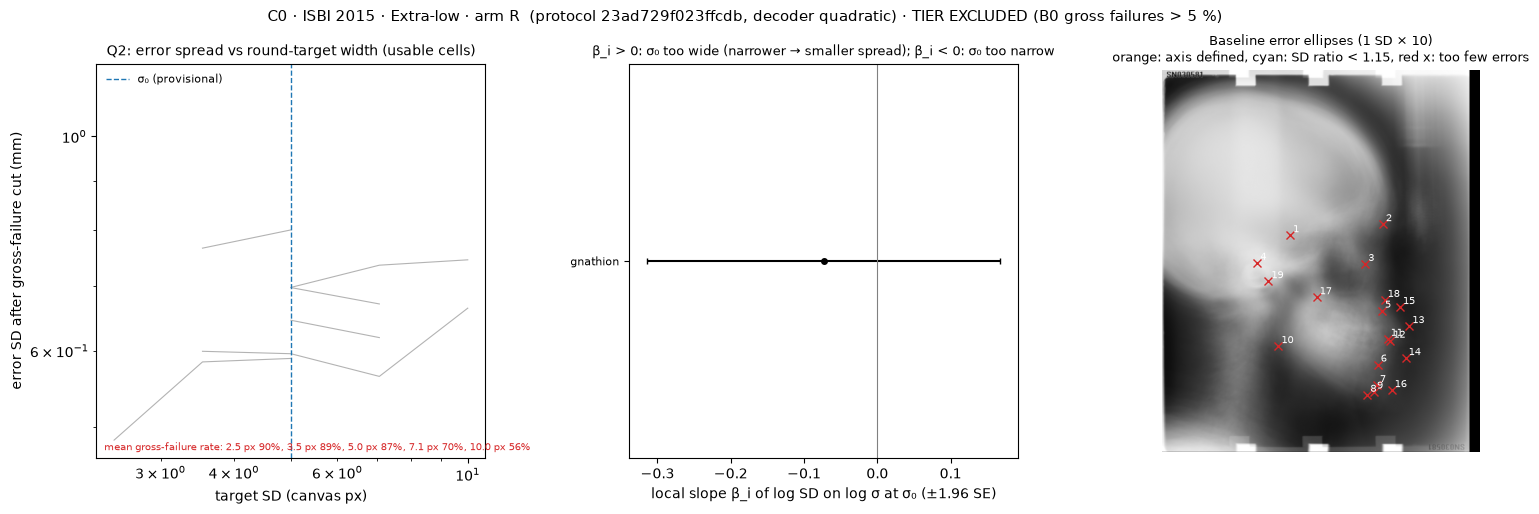

In [17]:
if HAVE_LOCK:
    try:
        fig, axs = plt.subplots(1, 3, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.1, 1.1, 0.9]})
        ax = axs[0]
        for lm, g in paired[paired.usable].groupby("landmark"):
            m = g.groupby("width_mult").sd_iso.apply(lambda v: np.exp(np.log(v).mean()))
            ax.plot(m.index * SIGMA0_PX, m.values, color="0.7", lw=0.8)
        if not pooled.empty:
            ax.plot(np.array(pooled.index) * SIGMA0_PX, np.exp(pooled.values), color="k", lw=2, marker="o",
                    label=f"geometric mean, {len(ok_lm)} landmarks usable at all eligible widths")
        ax.axvline(SIGMA0_PX, color="tab:blue", ls="--", lw=1, label="σ₀ (provisional)")
        fr = paired.groupby("width_mult").fail_rate.mean()
        ax.text(0.02, 0.02, "mean gross-failure rate: " + ", ".join(f"{w * SIGMA0_PX:.1f} px {f:.0%}" for w, f in fr.items()),
                transform=ax.transAxes, fontsize=7, color="tab:red")
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel("target SD (canvas px)"); ax.set_ylabel("error SD after gross-failure cut (mm)")
        ax.set_title("Q2: error spread vs round-target width (usable cells)", fontsize=10); ax.legend(frameon=False, fontsize=8)

        ax = axs[1]
        q = Q2.dropna(subset=["beta"]).sort_values("beta")
        if len(q):
            ax.errorbar(q.beta, range(len(q)), xerr=1.96 * q.beta_se, fmt="o", color="k", ms=4, capsize=2)
            ax.set_yticks(range(len(q))); ax.set_yticklabels(q.name, fontsize=8)
        else:
            ax.text(0.5, 0.5, "no landmark has enough usable cells", ha="center", transform=ax.transAxes)
        ax.axvline(0, color="0.5", lw=0.8)
        ax.set_xlabel("local slope β_i of log SD on log σ at σ₀ (±1.96 SE)")
        ax.set_title("β_i > 0: σ₀ too wide (narrower → smaller spread); β_i < 0: σ₀ too narrow", fontsize=9)

        ax = axs[2]
        ax.imshow(np.mean([DATA[i]["img"].astype(np.float32) for i in TRAIN_IDS], 0), cmap="gray")
        mean_xy = np.mean([DATA[i]["gt_canvas"] for i in TRAIN_IDS], 0)
        k_scale = 10.0
        mm_to_canvas = DATA[1]["s"] / MM
        for _, a in AXES.iterrows():
            x, y = mean_xy[int(a.landmark) - 1]
            if np.isfinite(a.sd_major_mm):
                ax.add_patch(Ellipse((x, y), 2 * k_scale * a.sd_major_mm * mm_to_canvas, 2 * k_scale * a.sd_minor_mm * mm_to_canvas,
                                     angle=a.angle_major_deg_measured, fill=False, lw=1.2,
                                     ec="tab:orange" if a.axis_defined else "tab:cyan"))
            else:
                ax.plot(x, y, "x", color="tab:red", ms=6)
            ax.text(x + 6, y - 6, str(int(a.landmark)), color="w", fontsize=7)
        ax.set_title(f"Baseline error ellipses (1 SD × {k_scale:g})\norange: axis defined, cyan: SD ratio < 1.15, "
                     "red x: too few errors", fontsize=9)
        ax.axis("off")
        status = "" if tier_ok else " · TIER EXCLUDED (B0 gross failures > 5 %)"
        fig.suptitle(f"C0 · ISBI 2015 · {TIER} · arm R  (protocol {PROTOCOL_HASH}, decoder {PD}){status}", fontsize=11)
        fig.tight_layout()
        fig.savefig(AGG / "arm_R_overview.png", dpi=200)
    finally:
        _LOCK.unlink(missing_ok=True)

## 11. Results to report

In [18]:
for name in ("tier_status.json", "sigma0_decision.json"):
    print(f"--- {name}\n" + (AGG / name).read_text())
FAIL_BY_WIDTH = pd.read_csv(AGG / "fail_by_width.csv")
FAIL_BY_WIDTH

--- tier_status.json
{
 "tier": "Extra-low",
 "qualifies_for_transfer_and_capacity_analyses": false,
 "limit": 0.05,
 "b0_fail_rate_by_run": {
  "C0_ISBI2015_Extra-low_R_w1.00_s101": 1.0,
  "C0_ISBI2015_Extra-low_R_w1.00_s102": 1.0,
  "C0_ISBI2015_Extra-low_R_w1.00_s1": 0.6219,
  "C0_ISBI2015_Extra-low_R_w1.00_s2": 1.0,
  "C0_ISBI2015_Extra-low_R_w1.00_s3": 1.0
 },
 "note": "1 x sigma0 runs exceed the gross-failure limit: report this tier descriptively only (detector breaks down under the fixed protocol)"
}
--- sigma0_decision.json
{
 "sigma0_provisional_px": 5.0,
 "reference_landmarks": [],
 "excluded_failing_at_baseline": [
  "sella",
  "nasion",
  "orbitale",
  "porion",
  "subspinale (A)",
  "supramentale (B)",
  "pogonion",
  "menton",
  "gnathion",
  "gonion",
  "lower incisal incision",
  "upper incisal incision",
  "upper lip",
  "lower lip",
  "subnasale",
  "soft-tissue pogonion",
  "posterior nasal spine",
  "anterior nasal spine",
  "articulare"
 ],
 "usable_cell_share_all_

,landmark,0.50,0.71,1.00,1.41,2.00
0,1,1.0000,1.0000,1.0000,1.0000,0.6707
1,2,1.0000,1.0000,1.0000,0.8720,0.4867
2,3,1.0000,1.0000,1.0000,1.0000,0.6760
3,4,1.0000,1.0000,1.0000,1.0000,0.6947
4,5,0.7373,0.7587,1.0000,0.6707,0.6480
5,6,0.9533,0.9987,1.0000,0.8600,0.5787
6,7,0.9720,0.9827,0.6707,0.3133,0.2467
7,8,1.0000,0.9653,0.6693,0.3387,0.4120
8,9,1.0000,0.6747,0.6707,0.3360,0.0027
9,10,1.0000,1.0000,1.0000,1.0000,1.0000
